# 2. Backing Off

> **Overview.** Noisy linear decoys fool error times explained fraction (notebook 1), and only the results of the LTUs
> tried on an output can show that they do not help. Can search back off from an output each time a new LTU on it
> fails?

**Setup.** Notebook 1's problem, learner and runs. Each new LTU gets a parent output, drawn:
- uniformly (baseline: the current method);
- in proportion to its error times its explained fraction, $L_o e_o$ (notebook 1);
- **with back-off** (proposed): in proportion to $L_o e_o$, but not from outputs that sit out. Search judges each new
  LTU at its 8th search step, or earlier if it replaces it. The LTU succeeds if it removes more than 1/32 of its
  parent's error, and fails otherwise. When an LTU fails, its parent sits out the next $2^k$ search steps, where $k$ is
  the number of times the parent sat out since its last success. A failure during a sit-out does not count. A success
  ends the sit-out and sets $k$ to 0;
- by an oracle, in proportion to $L_o$, but only among the outputs that read target LTUs (reference).

In [1]:
import os
from time import perf_counter
from typing import NamedTuple

os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'   # take GPU memory only as needed, so the GPU can be shared
import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_INPUTS = 400
N_TARGETS = 8                        # target LTUs at first
N_SOURCES = 10                       # inputs each target LTU reads, drawn at random
N_OUTPUTS = 20
N_LEARNABLE = 2                      # the first outputs, each reading target LTUs; the rest are decoys
OUTPUT_FAN_IN = 4                    # target LTUs each of them reads, drawn at random
NOISE_STDS = (0.1, 1.0)              # noise on the outputs that read target LTUs: the lowest RMSE possible
N_CHANGES = 4                        # changes: a decoy becomes a target, reading N_NEW new target LTUs
FIRST_CHANGE, CHANGE_EVERY = 200_000, 100_000
N_NEW = 2
N_ALL_TARGETS = N_TARGETS + N_NEW * N_CHANGES

# --- Learner ---
STAT_RATE, VAR_FLOOR = 1e-3, 0.01    # standardization of the LTUs
INIT_STEP_SIZE = 1e-4                # Autostep's initial step-size
META_STEP_SIZE, TAU = 0.02, 1e4
N_LTUS = 32
FAST_STEP_SIZE = 3e-2                # initial step-size of a new LTU's input weights
GROW_Z = 6.0                         # an LTU connects an input whose gradient sum is this many RMS above the rest
FAN_IN = 20                          # a new LTU first reads this many inputs
REPLACED = 4                         # LTUs replaced at each search step, the least useful
JUDGE_AT = N_LTUS // REPLACED        # search steps after which a new LTU is judged: search has passed every slot
SUCCESS = 1 / N_LTUS                 # a new LTU succeeds if it removes more than this share of its parent's error

# --- Experiment ---
NUM_STEPS = 600_000
WINDOW = 1_000                       # steps per recorded RMSE
N_SEEDS = 5
PERIOD = 10_000                      # steps between search steps
UNIFORM, EXPLAINED, BACK_OFF, ORACLE = range(4)   # how a new LTU's parent output is drawn
NOISE, NOISY_LINEAR = range(2)                 # kinds of decoy

## Target

In [3]:
class Target(NamedTuple):
    w: jax.Array                # (N_ALL_TARGETS, N_INPUTS): the target LTUs' weights, +-1 on the inputs they read
    out: jax.Array              # (N_CHANGES + 1, N_OUTPUTS, N_ALL_TARGETS): the outputs' weights on them, by version
    linear: jax.Array           # (N_CHANGES + 1, N_OUTPUTS, N_INPUTS): the decoys' linear weights, by version
    noise_std: jax.Array        # (N_CHANGES + 1, N_OUTPUTS): each output's noise, by version


def make_target(key, kind, noise_std):
    # Version 0: the first N_LEARNABLE outputs each read OUTPUT_FAN_IN of the first N_TARGETS target LTUs, drawn at
    # random, with random +-1 weights scaled to unit variance, plus noise of std noise_std. The others (decoys) are noise
    # of std 1, plus, if kind is NOISY_LINEAR, a linear function of N_SOURCES random inputs (its own, drawn for every
    # output) with random +-1 weights scaled to unit variance. Each target LTU reads N_SOURCES random inputs, with random
    # +-1 weights. Change c makes version c + 1: a decoy, at random, reads the next N_NEW target LTUs instead, with
    # noise of std noise_std.
    read_key, w_key, out_key, out_w_key, change_key, linear_key, linear_w_key = jax.random.split(key, 7)
    pick = lambda k, shape, n: jnp.argsort(jnp.argsort(jax.random.uniform(k, shape))) < n   # n random entries per row
    w = (jax.random.rademacher(w_key, (N_ALL_TARGETS, N_INPUTS), dtype=float)
         * pick(read_key, (N_ALL_TARGETS, N_INPUTS), N_SOURCES))
    first = jnp.arange(N_OUTPUTS)[:, None] < N_LEARNABLE
    reads = jnp.pad(pick(out_key, (N_OUTPUTS, N_TARGETS), OUTPUT_FAN_IN), ((0, 0), (0, N_ALL_TARGETS - N_TARGETS)))
    out = (jax.random.rademacher(out_w_key, (N_OUTPUTS, N_ALL_TARGETS), dtype=float) * reads * first
           / np.sqrt(OUTPUT_FAN_IN))
    linear = (jax.random.rademacher(linear_w_key, (N_OUTPUTS, N_INPUTS), dtype=float)
              * pick(linear_key, (N_OUTPUTS, N_INPUTS), N_SOURCES) / np.sqrt(N_SOURCES) * (kind == NOISY_LINEAR))
    outs = [out]
    for c in range(N_CHANGES):
        sign_key, decoy_key = jax.random.split(jax.random.fold_in(change_key, c))
        targets = jnp.arange(N_ALL_TARGETS)
        new = (targets >= N_TARGETS + N_NEW * c) & (targets < N_TARGETS + N_NEW * (c + 1))
        decoy = jax.random.categorical(decoy_key, jnp.log(~(out != 0).any(1)))
        out = out.at[decoy].set(jax.random.rademacher(sign_key, (N_ALL_TARGETS,), dtype=float) * new / np.sqrt(N_NEW))
        outs.append(out)
    out = jnp.stack(outs)
    learnable = (out != 0).any(2)
    return Target(w, out, linear * ~learnable[..., None], jnp.where(learnable, noise_std, 1.0))


def sample(target, version, key):
    # One input and its noisy targets, under the given version of the target.
    x_key, noise_key = jax.random.split(key)
    x = jax.random.normal(x_key, (N_INPUTS,))
    return x, (target.out[version] @ jnp.where(target.w @ x > 0, 1.0, -1.0) + target.linear[version] @ x
               + target.noise_std[version] * jax.random.normal(noise_key, (N_OUTPUTS,)))

## Learner

In [4]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


@jax.custom_vjp
def standardize(bits, mean, error_mean, error_h_mean):
    return (bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))


def standardize_fwd(bits, mean, error_mean, error_h_mean):
    variance = mean * (1 - mean)
    scale = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    h = (bits - mean) / scale
    return h, (h, scale, variance > VAR_FLOOR, error_mean, error_h_mean)


def standardize_bwd(saved, g):
    h, scale, unfloored, error_mean, error_h_mean = saved
    return (g - error_mean - jnp.where(unfloored, h * error_h_mean, 0.)) / scale, None, None, None


standardize.defvjp(standardize_fwd, standardize_bwd)


class Stats(NamedTuple):
    # Running statistics of the LTUs, each shaped (N_LTUS,).
    hidden_mean: jax.Array      # firing rate
    error_mean: jax.Array       # means of the error g arriving at each LTU, and of g * h
    error_h_mean: jax.Array


class Net(NamedTuple):
    # w['hidden'] is the LTUs' weights over [inputs, 1 (the bias)], of which each reads those in `reads`; w['output'] is
    # the outputs' weights over [inputs (the linear learner), LTUs, 1].
    w: dict                     # {'hidden': (N_LTUS, N_INPUTS + 1), 'output': (N_OUTPUTS, N_INPUTS + N_LTUS + 1)}
    reads: jax.Array            # shaped like w['hidden']
    opt: IDBDState
    stats: Stats
    shadow: jax.Array           # (N_OUTPUTS, N_LTUS): each LTU's shadow weight, +-1 on one output (its parent), 0 elsewhere
    candidates: jax.Array       # (N_LTUS, N_INPUTS): each LTU's sums of dL/dz * x_i since its last new connection
    loss_sum: jax.Array         # (N_OUTPUTS,): each output's summed squared error since the last search step
    target_sum: jax.Array       # (N_OUTPUTS,): each output's targets, and their squares, summed likewise
    target_sq_sum: jax.Array
    added: jax.Array            # (N_LTUS,): the search step that added it (-1: the first LTUs, never judged)
    birth: jax.Array            # (N_LTUS,): its parent's mean squared error over the search period before it was added
    k: jax.Array                # (N_OUTPUTS,): times it sat out since its last success
    back: jax.Array             # (N_OUTPUTS,): the search step from which it can be a parent again


def init_net(key):
    # N_LTUS new LTUs with uniform parents, reading random inputs with random signs (no output has weights yet); every
    # other weight 0.
    w = {'hidden': jnp.zeros((N_LTUS, N_INPUTS + 1)), 'output': jnp.zeros((N_OUTPUTS, N_INPUTS + N_LTUS + 1))}
    stats = Stats(jnp.full(N_LTUS, 0.5), jnp.zeros(N_LTUS), jnp.zeros(N_LTUS))
    net = Net(w, jnp.zeros(w['hidden'].shape, bool), OPTIMIZER.init(w), stats, jnp.zeros((N_OUTPUTS, N_LTUS)),
              jnp.zeros((N_LTUS, N_INPUTS)), *(jnp.zeros(N_OUTPUTS),) * 3, jnp.full(N_LTUS, -1), jnp.ones(N_LTUS),
              jnp.zeros(N_OUTPUTS, int), jnp.zeros(N_OUTPUTS, int))
    return rewire(net, key, jnp.ones(N_LTUS, bool), jnp.zeros(N_OUTPUTS), False, False)


def rewire(net, key, replaced, parent_logits, parent, signs):
    # Each `replaced` LTU becomes a new LTU. Its shadow weight, +1 or -1 by slot, goes on its parent, an output drawn
    # with log-probabilities parent_logits. It reads FAN_IN inputs and the bias, the inputs drawn without replacement
    # with probability proportional to the square of the parent's linear weight on each if parent, uniformly otherwise
    # (Gumbel top-k), with LeCun uniform weights, taking the signs of its shadow weight times the parent's linear
    # weights if signs, at step-size FAST_STEP_SIZE. Its output weights are 0, and its statistics, Autostep state and
    # gradient sums fresh.
    out_key, draw_key, w_key = jax.random.split(key, 3)
    sign = jnp.where(jnp.arange(N_LTUS) % 2 == 0, 1.0, -1.0)
    new_parent = jax.random.categorical(out_key, parent_logits, shape=(N_LTUS,))
    shadow = jnp.where(replaced, (jnp.arange(N_OUTPUTS)[:, None] == new_parent) * sign, net.shadow)
    parent_w = shadow.T @ net.w['output'][:, :N_INPUTS]      # each LTU's shadow weight times its parent's linear weights
    scores = jnp.where(parent, jnp.log(parent_w ** 2), 0.0) + jax.random.gumbel(draw_key, parent_w.shape)
    inputs = jnp.argsort(jnp.argsort(-scores)) < FAN_IN
    w = jax.random.uniform(w_key, inputs.shape, minval=-1.0, maxval=1.0) * jnp.sqrt(3.0 / FAN_IN) * inputs
    w = jnp.where(signs, jnp.abs(w) * jnp.sign(parent_w), w)

    where = {'hidden': replaced[:, None],
             'output': jnp.concatenate([jnp.zeros(N_INPUTS, bool), replaced, jnp.zeros(1, bool)])[None]}
    reset = lambda tree, fresh: jax.tree.map(lambda m, a, b: jnp.where(m, a, b), where, fresh, tree)
    zeros = jax.tree.map(jnp.zeros_like, net.w)
    fast = jnp.append(inputs, jnp.zeros((N_LTUS, 1), bool), axis=1)
    beta = {'hidden': jnp.where(fast, jnp.log(FAST_STEP_SIZE), net.opt.init_beta),
            'output': zeros['output'] + net.opt.init_beta}
    opt = net.opt._replace(beta=reset(net.opt.beta, beta), h=reset(net.opt.h, zeros), v=reset(net.opt.v, zeros))
    stats = Stats(*(jnp.where(replaced, fresh, old) for fresh, old in zip((0.5, 0.0, 0.0), net.stats)))
    return net._replace(w=reset(net.w, {'hidden': jnp.append(w, jnp.zeros((N_LTUS, 1)), axis=1),
                                        'output': zeros['output']}),
                        reads=jnp.where(replaced[:, None], jnp.append(inputs, jnp.ones((N_LTUS, 1), bool), axis=1),
                                        net.reads),
                        opt=opt, stats=stats, shadow=shadow, candidates=jnp.where(replaced[:, None], 0.0, net.candidates))


def learn(net, x, y):
    # One online network-Autostep update on half the squared error summed over the outputs, each LTU's shadow weight
    # standing in for its weight to its parent in the backward pass while the real one is smaller than 1 in magnitude.
    # Returns the new network and each output's squared error on this sample, before learning from it, which it also
    # adds to loss_sum; adds the targets and their squares to target_sum and target_sq_sum, and dL/dz * x_i to each
    # LTU's gradient sums. `probe` is zero; its gradients are the error arriving at each LTU and dL/dz.

    def loss_fn(w, probe):
        b = ltu((w['hidden'] * net.reads) @ jnp.append(x, 1.0) + probe[1])
        mean = net.stats.hidden_mean + STAT_RATE * (jax.lax.stop_gradient(b) - net.stats.hidden_mean)
        a = standardize(b, mean, net.stats.error_mean, net.stats.error_h_mean) + probe[0]
        source = jnp.concatenate([x, a, jnp.ones(1)])
        unit_w = w['output'][:, N_INPUTS:-1]
        back = jax.lax.stop_gradient(jnp.where((net.shadow != 0) & (jnp.abs(unit_w) < 1.0), net.shadow, unit_w)) @ a
        prediction = w['output'] @ jax.lax.stop_gradient(source) + back - jax.lax.stop_gradient(back)
        return 0.5 * jnp.sum((prediction - y) ** 2), (jax.lax.stop_gradient(source), jax.lax.stop_gradient(a), mean,
                                                      jax.lax.stop_gradient(prediction - y) ** 2)

    (_, (source, h, mean, squared)), (grads, (error, dz)) = jax.value_and_grad(loss_fn, (0, 1), has_aux=True)(
        net.w, (jnp.zeros(N_LTUS),) * 2)
    grads = {**grads, 'hidden': grads['hidden'] * net.reads}
    sources = {'hidden': jnp.append(x, 1.0) * net.reads, 'output': jnp.broadcast_to(source, net.w['output'].shape)}
    updates, opt = OPTIMIZER.update((grads, None, sources), net.opt, net.w)
    stats = Stats(mean, net.stats.error_mean + STAT_RATE * (error - net.stats.error_mean),
                  net.stats.error_h_mean + STAT_RATE * (error * h - net.stats.error_h_mean))
    return net._replace(w=jax.tree.map(jnp.add, net.w, updates), opt=opt, stats=stats,
                        candidates=net.candidates + dz[:, None] * x, loss_sum=net.loss_sum + squared,
                        target_sum=net.target_sum + y, target_sq_sum=net.target_sq_sum + y ** 2), squared


def grow(net):
    # Each LTU whose largest gradient sum, over the inputs it does not read, is more than GROW_Z times their root mean
    # square connects that input, at weight 0 with step-size FAST_STEP_SIZE, and restarts its sums.
    unread = ~net.reads[:, :N_INPUTS]
    sums = jnp.where(unread, jnp.abs(net.candidates), 0.0)
    rms = jnp.sqrt(jnp.sum(sums ** 2, 1) / unread.sum(1))
    grows = jnp.max(sums, 1) > GROW_Z * rms
    new = (jnp.arange(N_INPUTS + 1) == jnp.argmax(sums, 1)[:, None]) & grows[:, None]
    beta = jnp.where(new, jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(w={**net.w, 'hidden': jnp.where(new, 0.0, net.w['hidden'])}, reads=net.reads | new,
                        opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}),
                        candidates=jnp.where(grows[:, None], 0.0, net.candidates))


def usefulness(net):
    # Each LTU's sum of squared outgoing weights: about the increase in the squared error, summed over the outputs, if
    # it were removed (its activity has unit variance).
    return (net.w['output'][:, N_INPUTS:-1] ** 2).sum(0)


def parent_logits(net, rule, learnable, step):
    # Log-probabilities of each output being a new LTU's parent: uniform; or in proportion to its mean squared error L
    # over the last search period times its explained fraction (V - L) / V, with V its targets' variance and 0 if
    # negative (EXPLAINED), and 0 while it sits out (BACK_OFF); or in proportion to L, among only the outputs reading
    # target LTUs (ORACLE). Uniform if all are 0.
    loss = net.loss_sum / PERIOD
    variance = net.target_sq_sum / PERIOD - (net.target_sum / PERIOD) ** 2
    explained = jnp.maximum(variance - loss, 0.0) / jnp.maximum(variance, 1e-30)
    weight = jnp.select([rule == EXPLAINED, rule == BACK_OFF, rule == ORACLE],
                        [loss * explained, loss * explained * (step >= net.back), loss * learnable], jnp.ones(N_OUTPUTS))
    return jnp.log(jnp.where(weight.sum() > 0, weight, 1.0))


def judge(net, weakest, step):
    # New LTUs at their JUDGE_AT-th search step, or replaced before it, succeed if their squared weight to their parent
    # (about the error their removal would add there) is more than SUCCESS times the parent's mean squared error before
    # they were added, and fail otherwise. A success ends its parent's sit-out and sets its k to 0. A failure, if its
    # parent is not sitting out, makes the parent sit out the next 2^k search steps, and adds 1 to k.
    age = step - net.added
    judged = (net.added >= 0) & ((age == JUDGE_AT) | (weakest & (age < JUDGE_AT)))
    parent = jnp.argmax(jnp.abs(net.shadow), 0)
    success = net.w['output'][parent, N_INPUTS + jnp.arange(N_LTUS)] ** 2 > SUCCESS * net.birth
    won = jnp.zeros(N_OUTPUTS).at[parent].add(judged & success) > 0
    lost = (jnp.zeros(N_OUTPUTS).at[parent].add(judged & ~success) > 0) & ~won & (step >= net.back)
    return net._replace(k=jnp.where(won, 0, net.k + lost), back=jnp.where(won, step, jnp.where(lost, step + 2 ** net.k,
                                                                                               net.back)))

## Training

In [5]:
def pick(condition, a, b):
    # a where condition holds, b otherwise, for networks.
    return jax.tree.map(lambda u, v: jnp.where(condition, u, v), a, b)


def train(net, key, target, rule):
    # NUM_STEPS online network-Autostep steps on samples from `target`, its version changing at FIRST_CHANGE and every
    # CHANGE_EVERY steps after. The LTUs grow every WINDOW steps, and every PERIOD steps search judges new LTUs, replaces
    # the REPLACED least useful LTUs by new ones with parents drawn by `rule`, and the outputs' statistics restart. Returns, for each
    # window, the mean squared error over the outputs then reading target LTUs.

    def window(net, inputs):
        index, key = inputs
        version = jnp.clip((index * WINDOW - FIRST_CHANGE) // CHANGE_EVERY + 1, 0, N_CHANGES)
        learnable = (target.out[version] != 0).any(1)
        sample_key, wire_key = jax.random.split(key)
        net, squared = jax.lax.scan(lambda net, k: learn(net, *sample(target, version, k)), net,
                                    jax.random.split(sample_key, WINDOW))
        net = grow(net)
        weakest = jnp.zeros(N_LTUS, bool).at[jnp.argsort(usefulness(net))[:REPLACED]].set(True)
        step = (index + 1) * WINDOW // PERIOD              # search steps so far, this one included
        new = judge(net, weakest, step)
        new = rewire(new, wire_key, weakest, parent_logits(new, rule, learnable, step), True, True)
        parent = jnp.argmax(jnp.abs(new.shadow), 0)
        new = new._replace(added=jnp.where(weakest, step, new.added),
                           birth=jnp.where(weakest, (net.loss_sum / PERIOD)[parent], new.birth))
        zero = jnp.zeros(N_OUTPUTS)
        net = pick((index + 1) * WINDOW % PERIOD == 0,
                   new._replace(loss_sum=zero, target_sum=zero, target_sq_sum=zero), net)
        squared = squared.mean(0)
        return net, (squared * learnable).sum() / learnable.sum()

    n = NUM_STEPS // WINDOW
    return jax.lax.scan(window, net, (jnp.arange(n), jax.random.split(key, n)))[1]


def run(configs):
    # Each (decoy kind, noise std, rule) of configs on N_SEEDS seeds, vmapped together; seed s gives every run the same
    # target LTUs and inputs. Returns {config: the RMSE over the outputs then reading target LTUs, (seed, window)}.
    kind, noise, rule, seed = (jnp.array(v) for v in zip(*[(*c, s) for c in configs for s in range(N_SEEDS)]))
    keys = lambda k: jax.random.split(jax.random.PRNGKey(k), N_SEEDS)[seed]
    targets = jax.vmap(make_target)(keys(2), kind, noise)
    mse = jax.jit(jax.vmap(train))(jax.vmap(init_net)(keys(0)), keys(1), targets, rule)
    return dict(zip(configs, np.sqrt(np.asarray(mse)).reshape(len(configs), N_SEEDS, -1)))

## Runs

In [6]:
DECOYS = [(NOISE, 'noise decoys'), (NOISY_LINEAR, 'noisy linear decoys')]
RULES = [('uniform', 'baseline: current method', UNIFORM, 'tab:red'),
         ('error times explained fraction', 'notebook 1', EXPLAINED, 'tab:orange'),
         ('back-off', 'proposed', BACK_OFF, 'tab:blue'),
         ('oracle', 'reference: error, among only the outputs reading target LTUs', ORACLE, 'tab:gray')]
started = perf_counter()
results = run([(kind, noise, rule) for kind, _ in DECOYS for noise in NOISE_STDS for _, _, rule, _ in RULES])
print(f'{len(results) * N_SEEDS} runs in {perf_counter() - started:.0f}s')

80 runs in 59s


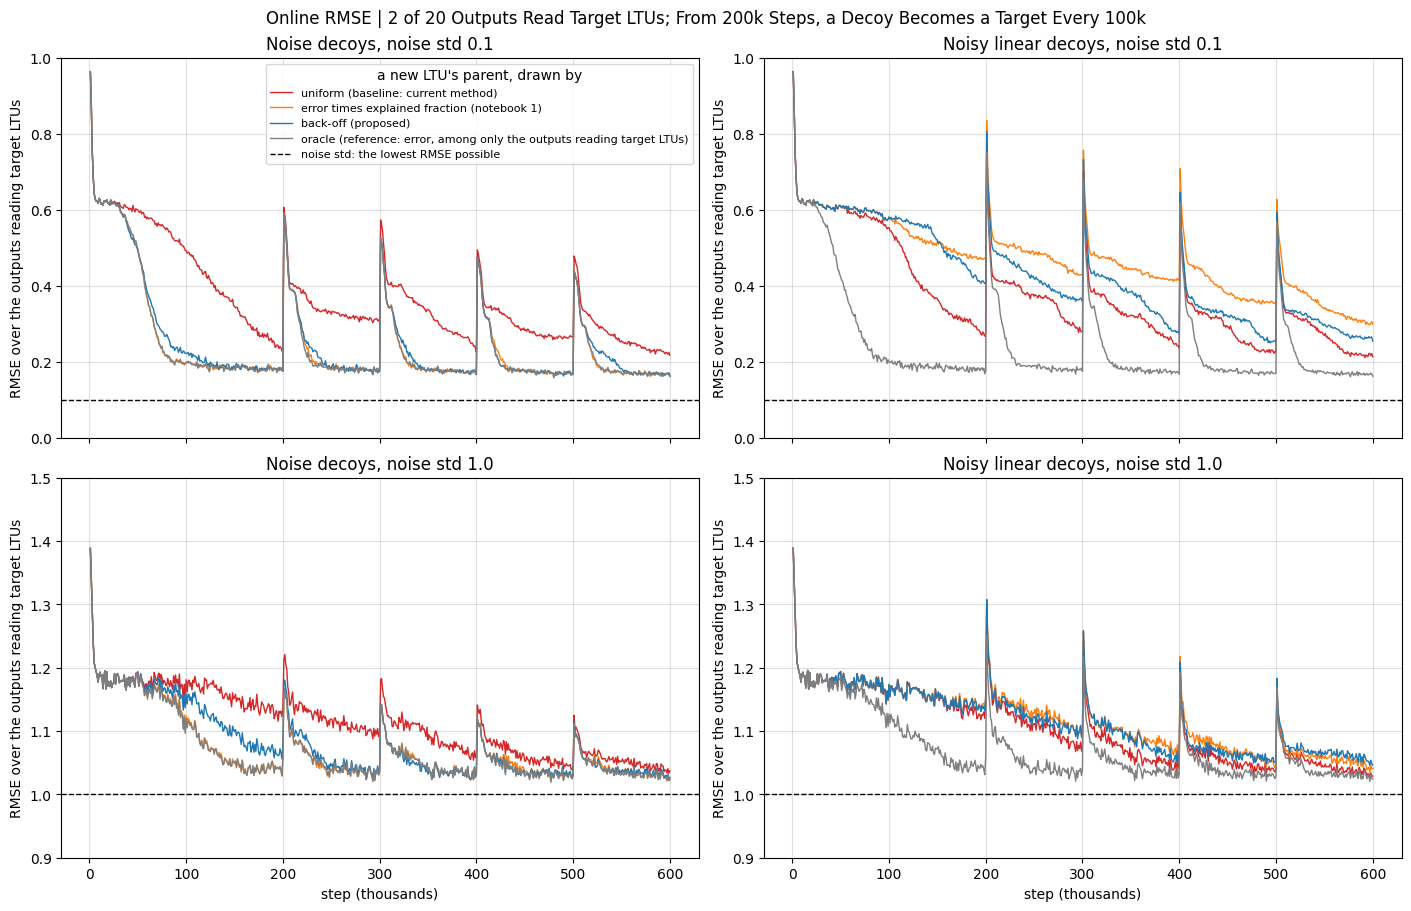

noise decoys, noise std 0.1, RMSE averaged over the run: uniform 0.368, error times explained fraction 0.249, back-off 0.255, oracle 0.247
noise decoys, noise std 1.0, RMSE averaged over the run: uniform 1.113, error times explained fraction 1.071, back-off 1.080, oracle 1.070
noisy linear decoys, noise std 0.1, RMSE averaged over the run: uniform 0.378, error times explained fraction 0.472, back-off 0.429, oracle 0.248
noisy linear decoys, noise std 1.0, RMSE averaged over the run: uniform 1.105, error times explained fraction 1.118, back-off 1.116, oracle 1.072


In [7]:
YLIMS = [(0, 1.0), (0.9, 1.5)]   # zoomed at noise std 1, where the gaps shrink near the floor
STEPS = (np.arange(NUM_STEPS // WINDOW) + 1) * WINDOW
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True, layout='constrained')
for column, (kind, decoys) in enumerate(DECOYS):
    for row, (noise, ylim) in enumerate(zip(NOISE_STDS, YLIMS)):
        ax = axes[row, column]
        for name, role, rule, color in RULES:
            ax.plot(STEPS / 1000, results[(kind, noise, rule)].mean(0), color=color, lw=1, label=f'{name} ({role})')
        ax.axhline(noise, color='black', ls='--', lw=1, label='noise std: the lowest RMSE possible')
        ax.set(title=f'{decoys.capitalize()}, noise std {noise}', ylim=ylim,
               ylabel='RMSE over the outputs reading target LTUs')
        ax.grid(alpha=0.4)
for ax in axes[1]:
    ax.set(xlabel='step (thousands)')
axes[0, 0].legend(title="a new LTU's parent, drawn by", fontsize=8)
fig.suptitle('Online RMSE | 2 of 20 Outputs Read Target LTUs; From 200k Steps, a Decoy Becomes a Target Every 100k')
plt.show()

for kind, decoys in DECOYS:
    for noise in NOISE_STDS:
        print(f'{decoys}, noise std {noise}, RMSE averaged over the run: '
              + ', '.join(f'{name} {results[(kind, noise, rule)].mean():.3f}' for name, _, rule, _ in RULES))

## Results

**With noise decoys**, back-off does about as well as error times explained fraction (RMSE averaged over the run 0.255
against 0.249 at noise std 0.1, and 1.080 against 1.071 at noise std 1), near the oracle (0.247 and 1.070).

**With noisy linear decoys**, back-off does better than error times explained fraction (0.43 against 0.47 at noise std
0.1), but worse than uniform parents (0.38), and far from the oracle (0.25). At noise std 1, the three are within 0.015
of each other (1.116, 1.118 and 1.105), against 1.072 for the oracle.

**Back-off starts too slowly.** Each judgment takes 8 search steps, but a decoy's first sit-outs last only 1, 2 and 4
search steps. So in the first 200k steps, decoys sit out only about a quarter of the time. While they do not, error
times explained fraction gives them most new LTUs: 6% go to the learnable outputs, against about 10% with uniform
parents. The judgments themselves are right: of the roughly 900 new LTUs on decoys that search judged, none succeeded.

## Details

**When to judge.** A new LTU shows its result late: for tens of thousands of steps, its weight to its parent stays
near 0, on learnable outputs and on decoys alike. Search judges it after 8 search steps, the time that search takes to
pass over all 32 slots (32 LTUs, 4 replaced per step), so the rule adds no new setting. Survival alone shows too
little at that age: search replaces any of the many useless LTUs, so about a quarter of the LTUs on decoys still live
after 8 search steps. Their weights tell the two kinds apart: then, the median LTU on a learnable output removes 0.09
to 0.6 of its parent's error, and on a decoy about 0.0001.

**Success.** 1/32 is one LTU's share if all 32 served one output equally.

**Failures during a sit-out.** Search can add several LTUs to an output before it judges the first. If each of their
failures counted, an output's sit-outs would double several times at once, and search would not try it again soon
after it changes. As it is, search tries an output again within about as long as it has been sitting out.

The rest is as in notebook 1.